
Failure pattern: distributed
Inactive indices: [0, 4, 9, 13, 18, 22, 27, 31]
Linear metrics: {'MAE': 0.07952429615317717, 'RMSE': 0.10361393324144637, 'Max_Absolute_Error': 0.2932466279790429}
Spline metrics: {'MAE': 0.024159731044866403, 'RMSE': 0.03334402690013598, 'Max_Absolute_Error': 0.11602437343920613}

Failure pattern: periodic
Inactive indices: [1, 5, 9, 13, 17, 21, 25, 29]
Linear metrics: {'MAE': 0.021956865000956137, 'RMSE': 0.03271810946243454, 'Max_Absolute_Error': 0.13835454087431742}
Spline metrics: {'MAE': 0.0040471658549425015, 'RMSE': 0.0064461876578149075, 'Max_Absolute_Error': 0.019544590249953586}

Failure pattern: contiguous
Inactive indices: [12, 13, 14, 15, 16, 17, 18, 19]
Linear metrics: {'MAE': 0.1996056624236192, 'RMSE': 0.3181183651353587, 'Max_Absolute_Error': 0.833081725322323}
Spline metrics: {'MAE': 0.033516077947516806, 'RMSE': 0.05500038067895848, 'Max_Absolute_Error': 0.183839779789416}


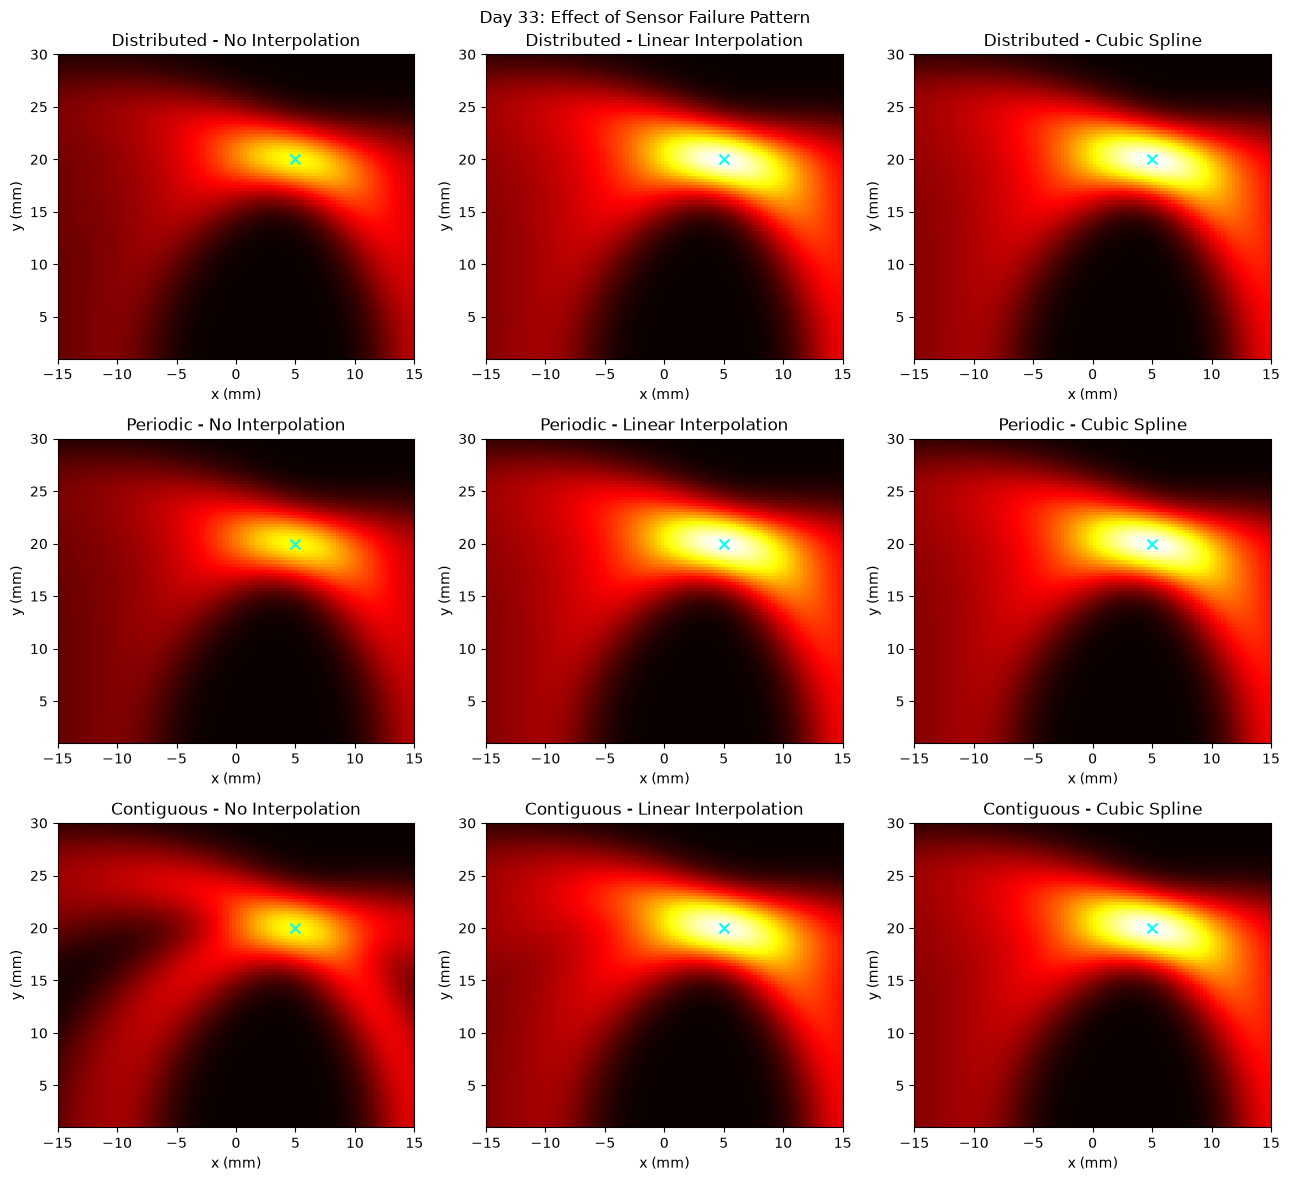

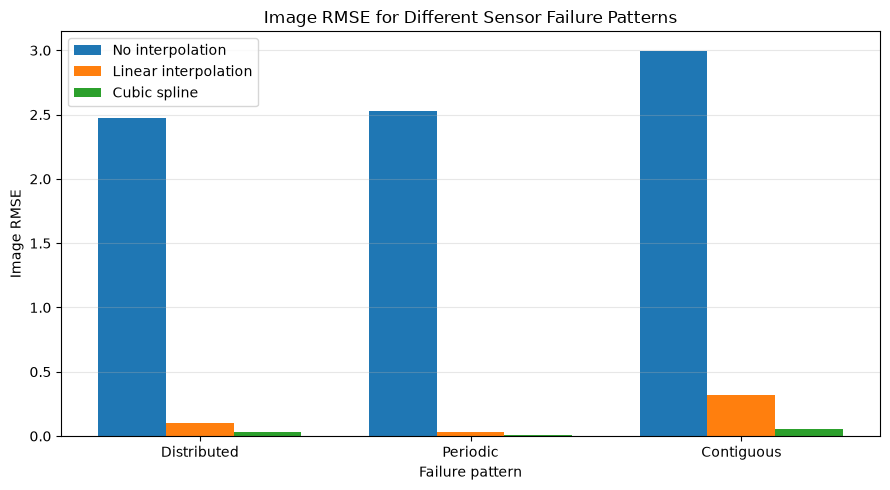


Results saved to: ..\outputs\day33_sensor_failure_pattern_results.json
Day 33 completed successfully!


In [1]:

import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

# --------------------------------------------------
# Day 33: Effect of Sensor Failure Patterns
# --------------------------------------------------

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Simulation settings
num_sensors = 32
fs = 10e6
c = 1500.0

time = np.arange(600) / fs
sensor_x = np.linspace(-15e-3, 15e-3, num_sensors)

source_x = 5e-3
source_y = 20e-3
pulse_width = 1.5e-6

# 2. Generate synthetic signals
signals_full = np.zeros((num_sensors, len(time)))

for i, sx in enumerate(sensor_x):
    distance = np.sqrt((sx - source_x)**2 + source_y**2)
    arrival_time = distance / c

    signals_full[i] = np.exp(
        -0.5 * ((time - arrival_time) / pulse_width)**2
    )

# 3. Image grid
x_grid = np.linspace(-15e-3, 15e-3, 100)
y_grid = np.linspace(1e-3, 30e-3, 100)
X, Y = np.meshgrid(x_grid, y_grid)

# 4. DAS reconstruction
def das_reconstruction(sensor_signals):
    image = np.zeros_like(X, dtype=float)

    for i, sx in enumerate(sensor_x):
        distances = np.sqrt((X - sx)**2 + Y**2)
        delays = distances / c

        sampled = np.interp(
            delays.ravel(),
            time,
            sensor_signals[i],
            left=0.0,
            right=0.0
        ).reshape(X.shape)

        image += sampled

    return image

image_full = das_reconstruction(signals_full)

# 5. Interpolation methods
def linear_interpolation(signals_missing, active_mask):
    reconstructed = signals_missing.copy()

    for j in range(len(time)):
        reconstructed[:, j] = np.interp(
            sensor_x,
            sensor_x[active_mask],
            signals_missing[active_mask, j]
        )

    return reconstructed

def cubic_spline_interpolation(signals_missing, active_mask):
    reconstructed = signals_missing.copy()

    spline = CubicSpline(
        sensor_x[active_mask],
        signals_missing[active_mask, :],
        axis=0,
        bc_type="natural",
        extrapolate=True
    )

    reconstructed[~active_mask, :] = spline(
        sensor_x[~active_mask]
    )

    return reconstructed

def calculate_metrics(reference, estimate):
    error = estimate - reference

    return {
        "MAE": float(np.mean(np.abs(error))),
        "RMSE": float(np.sqrt(np.mean(error**2))),
        "Max_Absolute_Error": float(np.max(np.abs(error)))
    }

# 6. Define three failure patterns
failure_patterns = {
    "distributed": np.array([0, 4, 9, 13, 18, 22, 27, 31]),
    "periodic": np.arange(1, num_sensors, 4),
    "contiguous": np.arange(12, 20)
}

results = {}
plot_data = {}

# 7. Evaluate each pattern
for pattern_name, inactive_indices in failure_patterns.items():
    active_mask = np.ones(num_sensors, dtype=bool)
    active_mask[inactive_indices] = False

    signals_missing = signals_full.copy()
    signals_missing[~active_mask, :] = 0.0

    signals_linear = linear_interpolation(
        signals_missing, active_mask
    )
    signals_spline = cubic_spline_interpolation(
        signals_missing, active_mask
    )

    image_missing = das_reconstruction(signals_missing)
    image_linear = das_reconstruction(signals_linear)
    image_spline = das_reconstruction(signals_spline)

    results[pattern_name] = {
        "inactive_sensor_count": int(len(inactive_indices)),
        "inactive_ratio_percent": float(
            100 * len(inactive_indices) / num_sensors
        ),
        "inactive_indices_zero_based": inactive_indices.tolist(),
        "image_metrics_vs_full_sensor_baseline": {
            "no_interpolation": calculate_metrics(
                image_full, image_missing
            ),
            "linear_interpolation": calculate_metrics(
                image_full, image_linear
            ),
            "cubic_spline_interpolation": calculate_metrics(
                image_full, image_spline
            )
        }
    }

    plot_data[pattern_name] = {
        "missing": image_missing,
        "linear": image_linear,
        "spline": image_spline
    }

    print(f"\nFailure pattern: {pattern_name}")
    print("Inactive indices:", inactive_indices.tolist())
    print("Linear metrics:",
          results[pattern_name]
          ["image_metrics_vs_full_sensor_baseline"]
          ["linear_interpolation"])
    print("Spline metrics:",
          results[pattern_name]
          ["image_metrics_vs_full_sensor_baseline"]
          ["cubic_spline_interpolation"])

# 8. Plot reconstructed images
patterns = ["distributed", "periodic", "contiguous"]
methods = [
    ("missing", "No Interpolation"),
    ("linear", "Linear Interpolation"),
    ("spline", "Cubic Spline")
]

fig, axes = plt.subplots(3, 3, figsize=(13, 12))
vmax = max(float(np.max(image_full)), 1e-12)

for row, pattern_name in enumerate(patterns):
    for col, (method_key, method_title) in enumerate(methods):
        ax = axes[row, col]
        image = plot_data[pattern_name][method_key]

        ax.imshow(
            image,
            extent=[
                x_grid[0] * 1e3, x_grid[-1] * 1e3,
                y_grid[0] * 1e3, y_grid[-1] * 1e3
            ],
            origin="lower",
            aspect="auto",
            cmap="hot",
            vmin=0,
            vmax=vmax
        )

        ax.scatter(
            [source_x * 1e3],
            [source_y * 1e3],
            marker="x",
            color="cyan",
            s=50
        )

        ax.set_title(f"{pattern_name.title()} - {method_title}")
        ax.set_xlabel("x (mm)")
        ax.set_ylabel("y (mm)")

fig.suptitle("Day 33: Effect of Sensor Failure Pattern")
plt.tight_layout()

plt.savefig(
    output_dir / "day33_failure_pattern_reconstructions.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 9. Compare RMSE across failure patterns
linear_rmse = [
    results[p]["image_metrics_vs_full_sensor_baseline"]
    ["linear_interpolation"]["RMSE"]
    for p in patterns
]

spline_rmse = [
    results[p]["image_metrics_vs_full_sensor_baseline"]
    ["cubic_spline_interpolation"]["RMSE"]
    for p in patterns
]

missing_rmse = [
    results[p]["image_metrics_vs_full_sensor_baseline"]
    ["no_interpolation"]["RMSE"]
    for p in patterns
]

x = np.arange(len(patterns))
width = 0.25

plt.figure(figsize=(9, 5))
plt.bar(x - width, missing_rmse, width, label="No interpolation")
plt.bar(x, linear_rmse, width, label="Linear interpolation")
plt.bar(x + width, spline_rmse, width, label="Cubic spline")

plt.xticks(x, [p.title() for p in patterns])
plt.ylabel("Image RMSE")
plt.xlabel("Failure pattern")
plt.title("Image RMSE for Different Sensor Failure Patterns")
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    output_dir / "day33_failure_pattern_rmse.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 10. Save results
final_results = {
    "day": 33,
    "num_sensors": num_sensors,
    "inactive_sensor_count_per_pattern": 8,
    "inactive_ratio_percent": 25.0,
    "reference_note": (
        "Full-sensor synthetic DAS image; not experimental ground truth."
    ),
    "results_by_failure_pattern": results
}

with open(
    output_dir / "day33_sensor_failure_pattern_results.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(final_results, f, indent=4, ensure_ascii=False)

print("\nResults saved to:",
      output_dir / "day33_sensor_failure_pattern_results.json")
print("Day 33 completed successfully!")
